# Лабораторна робота №7
## Нейронна класифікація зображень у TensorFlow

**Студент:** Михайло Вахнюк  
**Варіант:** 5  

**Мета:** навчитися класифікувати зображення за допомогою нейронної мережі, порівняти дві моделі за validation-вибіркою та проаналізувати помилки класифікації.

**Набір даних:** Fashion-MNIST — 28×28 пікселів зображень одягу, розподілених на 10 класів.

**Індивідуальний варіант 5:** порівняти базову нейромережу з мережею, у якій `learning_rate` оптимізатора Adam зменшено з `0.001` до `0.0003`.

**Джерело:** https://github.com/zalandoresearch/fashion-mnist  
**Ліцензія:** MIT.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1


In [2]:
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка або топ",
    "Штани",
    "Светр",
    "Сукня",
    "Пальто",
    "Сандалі",
    "Сорочка",
    "Кросівки",
    "Сумка",
    "Черевики",
]

dev_indices = np.arange(len(x_dev))

train_indices, val_indices = train_test_split(
    dev_indices,
    test_size=0.20,
    stratify=y_dev,
    random_state=SEED,
)

x_train, y_train = x_dev[train_indices], y_dev[train_indices]
x_val, y_val = x_dev[val_indices], y_dev[val_indices]

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (48000, 28, 28) (48000,)
Validation: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


In [3]:
for name, images, labels in [
    ("Train", x_train, y_train),
    ("Validation", x_val, y_val),
    ("Test", x_test, y_test),
]:
    print(
        f"{name}: shape={images.shape}, dtype={images.dtype}, "
        f"пікселі={images.min()}–{images.max()}, "
        f"мітки={labels.min()}–{labels.max()}"
    )

    assert images.shape[1:] == (28, 28)
    assert labels.shape == (len(images),)
    assert images.min() >= 0 and images.max() <= 255
    assert set(np.unique(labels)) == set(range(10))

assert set(train_indices).isdisjoint(val_indices)

class_counts = pd.DataFrame({
    "Клас": class_names,
    "Train": np.bincount(y_train, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10),
})

display(class_counts)

Train: shape=(48000, 28, 28), dtype=uint8, пікселі=0–255, мітки=0–9
Validation: shape=(12000, 28, 28), dtype=uint8, пікселі=0–255, мітки=0–9
Test: shape=(10000, 28, 28), dtype=uint8, пікселі=0–255, мітки=0–9


,Клас,Train,Validation,Test
0,Футболка або топ,4800,1200,1000
1,Штани,4800,1200,1000
2,Светр,4800,1200,1000
3,Сукня,4800,1200,1000
4,Пальто,4800,1200,1000
5,Сандалі,4800,1200,1000
6,Сорочка,4800,1200,1000
7,Кросівки,4800,1200,1000
8,Сумка,4800,1200,1000
9,Черевики,4800,1200,1000


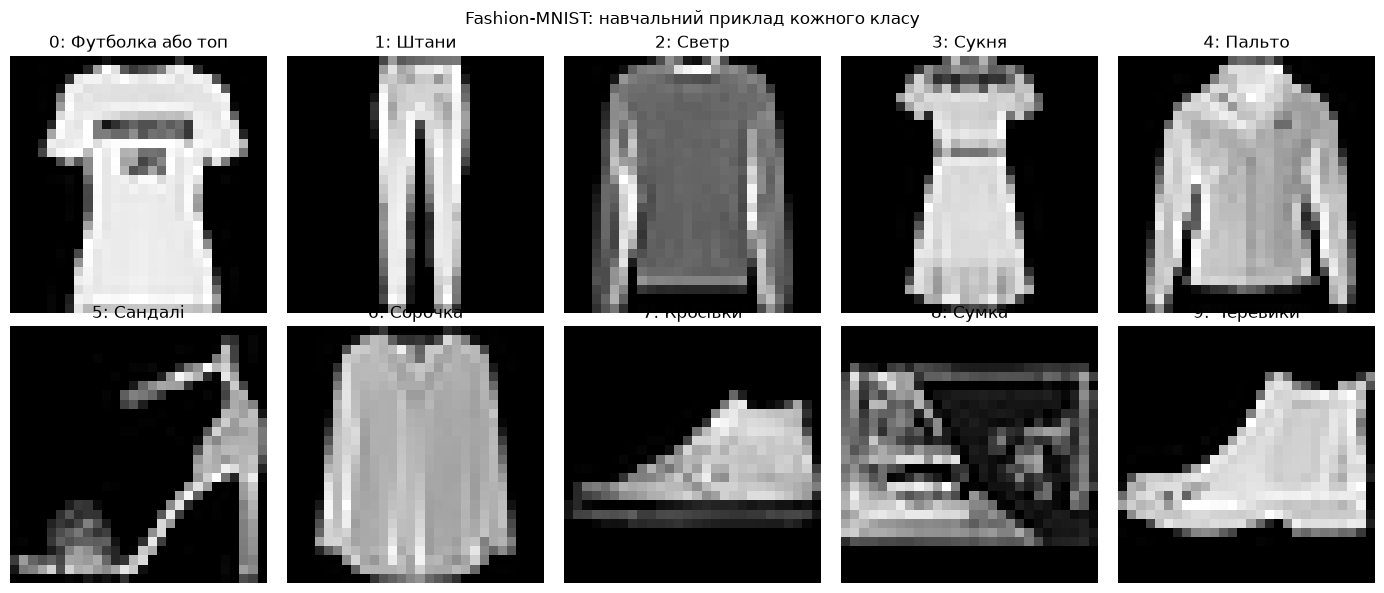

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for class_id, ax in enumerate(axes.flat):
    image_index = np.flatnonzero(y_train == class_id)[0]

    ax.imshow(x_train[image_index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{class_id}: {class_names[class_id]}")
    ax.axis("off")

fig.suptitle("Fashion-MNIST: навчальний приклад кожного класу")
plt.tight_layout()
plt.savefig("class_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

for name, images in [
    ("Train", x_train),
    ("Validation", x_val),
    ("Test", x_test),
]:
    assert images.dtype == np.float32
    assert images.shape[1:] == (28, 28)
    assert np.isfinite(images).all()
    assert images.min() >= 0 and images.max() <= 255

    print(
        f"{name}: dtype={images.dtype}, "
        f"діапазон={images.min():.0f}–{images.max():.0f}"
    )

Train: dtype=float32, діапазон=0–255
Validation: dtype=float32, діапазон=0–255
Test: dtype=float32, діапазон=0–255


In [6]:
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(
    x_train.reshape(len(x_train), -1),
    y_train,
)

dummy_val_pred = dummy_model.predict(
    x_val.reshape(len(x_val), -1)
)

dummy_val_accuracy = accuracy_score(y_val, dummy_val_pred)
dummy_val_macro_f1 = f1_score(
    y_val,
    dummy_val_pred,
    average="macro",
    zero_division=0,
)

display(pd.DataFrame([{
    "Модель": "DummyClassifier",
    "Validation accuracy": dummy_val_accuracy,
    "Validation macro-F1": dummy_val_macro_f1,
}]).round(4))

,Модель,Validation accuracy,Validation macro-F1
0,DummyClassifier,0.1,0.0182


In [7]:
def build_model(learning_rate=0.001):
    keras.utils.set_random_seed(SEED)

    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Rescaling(1.0 / 255),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=False
        ),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ],
    )

    return model


base_model = build_model(learning_rate=0.001)
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
base_checkpoint_path = artifacts_dir / "base_best.keras"

base_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(base_checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
    ),
]

history_base = base_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=base_callbacks,
    verbose=2,
)

base_best_model = keras.models.load_model(
    base_checkpoint_path
)

base_epochs = len(history_base.history["loss"])
base_best_epoch = int(
    np.argmin(history_base.history["val_loss"]) + 1
)

print("Виконано епох:", base_epochs)
print("Найкраща епоха:", base_best_epoch)
print(
    "Найменший validation loss:",
    min(history_base.history["val_loss"]),
)

Epoch 1/30
375/375 - 2s - 5ms/step - accuracy: 0.7988 - loss: 0.5887 - val_accuracy: 0.8217 - val_loss: 0.4879
Epoch 2/30
375/375 - 1s - 3ms/step - accuracy: 0.8515 - loss: 0.4202 - val_accuracy: 0.8403 - val_loss: 0.4431
Epoch 3/30
375/375 - 1s - 3ms/step - accuracy: 0.8662 - loss: 0.3768 - val_accuracy: 0.8532 - val_loss: 0.4090
Epoch 4/30
375/375 - 1s - 3ms/step - accuracy: 0.8750 - loss: 0.3487 - val_accuracy: 0.8675 - val_loss: 0.3743
Epoch 5/30
375/375 - 1s - 3ms/step - accuracy: 0.8816 - loss: 0.3279 - val_accuracy: 0.8726 - val_loss: 0.3596
Epoch 6/30
375/375 - 1s - 3ms/step - accuracy: 0.8873 - loss: 0.3111 - val_accuracy: 0.8793 - val_loss: 0.3435
Epoch 7/30
375/375 - 1s - 3ms/step - accuracy: 0.8919 - loss: 0.2962 - val_accuracy: 0.8831 - val_loss: 0.3342
Epoch 8/30
375/375 - 1s - 3ms/step - accuracy: 0.8967 - loss: 0.2844 - val_accuracy: 0.8853 - val_loss: 0.3252
Epoch 9/30
375/375 - 1s - 3ms/step - accuracy: 0.8999 - loss: 0.2738 - val_accuracy: 0.8850 - val_loss: 0.3275
E

In [9]:
variant_model = build_model(learning_rate=0.0003)
variant_model.summary()

variant_checkpoint_path = artifacts_dir / "variant5_best.keras"

variant_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(variant_checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
    ),
]

history_variant = variant_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=variant_callbacks,
    verbose=2,
)

variant_best_model = keras.models.load_model(
    variant_checkpoint_path
)

variant_epochs = len(history_variant.history["loss"])
variant_best_epoch = int(
    np.argmin(history_variant.history["val_loss"]) + 1
)

print("Виконано епох:", variant_epochs)
print("Найкраща епоха:", variant_best_epoch)
print(
    "Найменший validation loss:",
    min(history_variant.history["val_loss"]),
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
375/375 - 2s - 4ms/step - accuracy: 0.7644 - loss: 0.7368 - val_accuracy: 0.8349 - val_loss: 0.5029
Epoch 2/30
375/375 - 1s - 3ms/step - accuracy: 0.8371 - loss: 0.4782 - val_accuracy: 0.8526 - val_loss: 0.4385
Epoch 3/30
375/375 - 1s - 3ms/step - accuracy: 0.8515 - loss: 0.4315 - val_accuracy: 0.8613 - val_loss: 0.4090
Epoch 4/30
375/375 - 1s - 3ms/step - accuracy: 0.8594 - loss: 0.4037 - val_accuracy: 0.8668 - val_loss: 0.3906
Epoch 5/30
375/375 - 1s - 3ms/step - accuracy: 0.8647 - loss: 0.3838 - val_accuracy: 0.8703 - val_loss: 0.3779
Epoch 6/30
375/375 - 1s - 3ms/step - accuracy: 0.8695 - loss: 0.3681 - val_accuracy: 0.8732 - val_loss: 0.3685
Epoch 7/30
375/375 - 1s - 3ms/step - accuracy: 0.8747 - loss: 0.3549 - val_accuracy: 0.8745 - val_loss: 0.3614
Epoch 8/30
375/375 - 1s - 3ms/step - accuracy: 0.8784 - loss: 0.3436 - val_accuracy: 0.8769 - val_loss: 0.3537
Epoch 9/30
375/375 - 1s - 3ms/step - accuracy: 0.8815 - loss: 0.3338 - val_accuracy: 0.8781 - val_loss: 0.3482
E

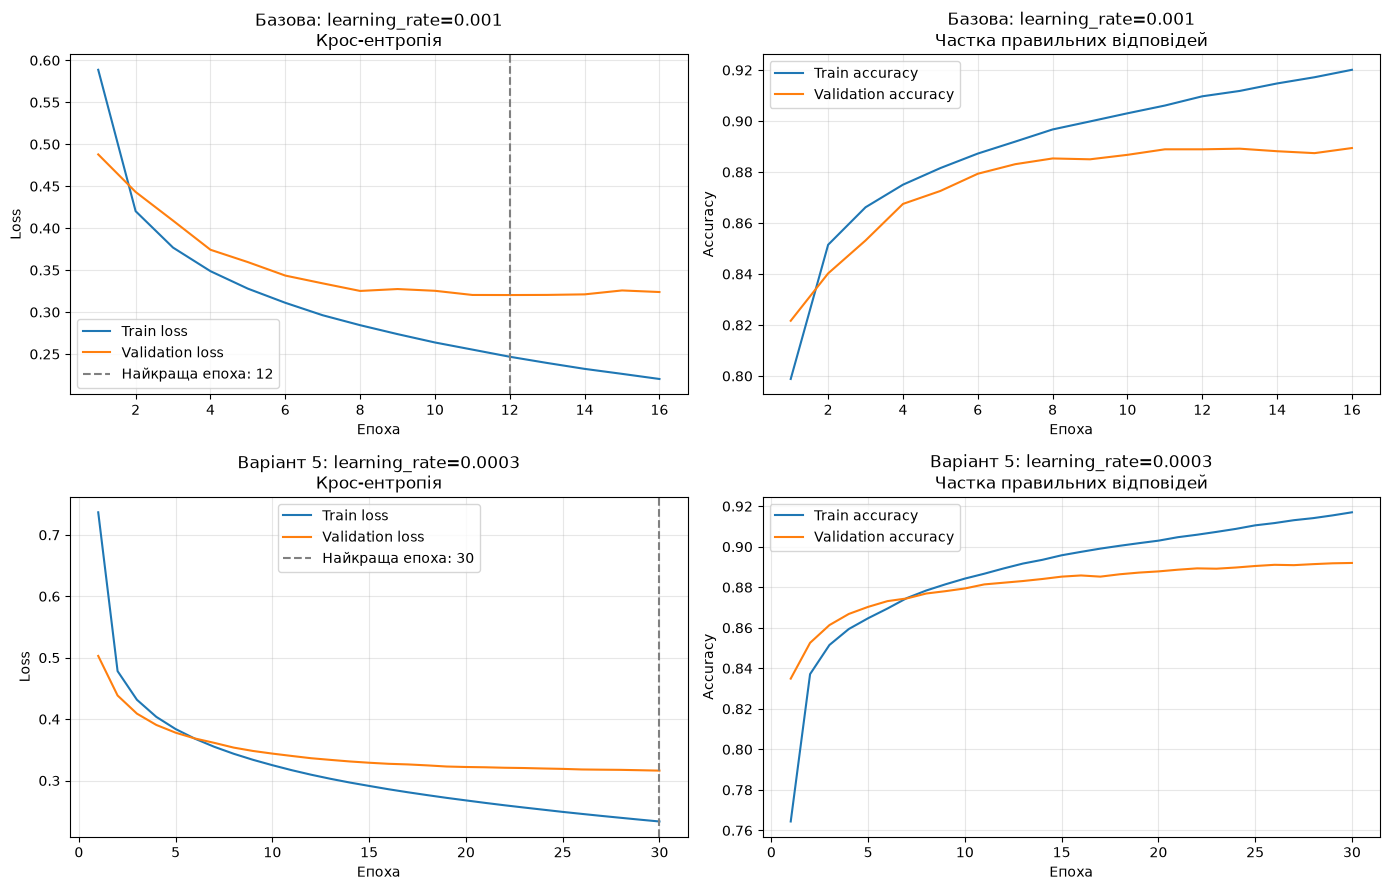

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

experiments = [
    ("Базова: learning_rate=0.001", history_base),
    ("Варіант 5: learning_rate=0.0003", history_variant),
]

for row, (title, history) in enumerate(experiments):
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    axes[row, 0].plot(
        epochs, history.history["loss"], label="Train loss"
    )
    axes[row, 0].plot(
        epochs, history.history["val_loss"], label="Validation loss"
    )
    axes[row, 0].axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label=f"Найкраща епоха: {best_epoch}",
    )
    axes[row, 0].set_title(f"{title}\nКрос-ентропія")
    axes[row, 0].set_xlabel("Епоха")
    axes[row, 0].set_ylabel("Loss")

    axes[row, 1].plot(
        epochs, history.history["accuracy"], label="Train accuracy"
    )
    axes[row, 1].plot(
        epochs,
        history.history["val_accuracy"],
        label="Validation accuracy",
    )
    axes[row, 1].set_title(f"{title}\nЧастка правильних відповідей")
    axes[row, 1].set_xlabel("Епоха")
    axes[row, 1].set_ylabel("Accuracy")

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
probe_labels = y_val[:5]

probe_probabilities = base_best_model(
    x_val[:5],
    training=False,
).numpy()

probe_onehot = keras.utils.to_categorical(
    probe_labels,
    num_classes=10,
)

sparse_loss = keras.losses.SparseCategoricalCrossentropy(
    from_logits=False
)(probe_labels, probe_probabilities)

onehot_loss = keras.losses.CategoricalCrossentropy(
    from_logits=False
)(probe_onehot, probe_probabilities)

np.testing.assert_allclose(
    sparse_loss.numpy(),
    onehot_loss.numpy(),
    rtol=1e-5,
)

print("Цілочисельні мітки:", probe_labels)
print("One-hot мітки:\n", probe_onehot.astype(int))
print("Sparse cross-entropy:", float(sparse_loss.numpy()))
print("One-hot cross-entropy:", float(onehot_loss.numpy()))
print("Перевірку пройдено: втрати збігаються.")

Цілочисельні мітки: [5 4 5 2 1]
One-hot мітки:
 [[0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0 0 0]]
Sparse cross-entropy: 0.07539533078670502
One-hot cross-entropy: 0.07539507001638412
Перевірку пройдено: втрати збігаються.


In [12]:
def classification_metrics(y_true, probabilities):
    assert probabilities.shape == (len(y_true), 10)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    np.testing.assert_allclose(
        probabilities.sum(axis=1),
        np.ones(len(y_true)),
        rtol=1e-5,
        atol=1e-5,
    )

    predictions = probabilities.argmax(axis=1)

    return {
        "cross_entropy": float(
            keras.losses.SparseCategoricalCrossentropy(
                from_logits=False
            )(y_true, probabilities).numpy()
        ),
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0,
        ),
    }


base_val_probabilities = base_best_model.predict(
    x_val, batch_size=256, verbose=0
)
variant_val_probabilities = variant_best_model.predict(
    x_val, batch_size=256, verbose=0
)

base_val_metrics = classification_metrics(
    y_val, base_val_probabilities
)
variant_val_metrics = classification_metrics(
    y_val, variant_val_probabilities
)

validation_results = pd.DataFrame([
    {
        "Модель": "Базова (lr=0.001)",
        **base_val_metrics,
        "Епох виконано": base_epochs,
        "Найкраща епоха": base_best_epoch,
    },
    {
        "Модель": "Варіант 5 (lr=0.0003)",
        **variant_val_metrics,
        "Епох виконано": variant_epochs,
        "Найкраща епоха": variant_best_epoch,
    },
])

if variant_val_metrics["cross_entropy"] < base_val_metrics["cross_entropy"]:
    selected_model = variant_best_model
    selected_model_name = "Варіант 5 (lr=0.0003)"
else:
    selected_model = base_best_model
    selected_model_name = "Базова (lr=0.001)"

display(validation_results.round(5))
print("Обрана за validation модель:", selected_model_name)

,Модель,cross_entropy,accuracy,macro_f1,Епох виконано,Найкраща епоха
0,Базова (lr=0.001),0.31974,0.88892,0.88983,16,12
1,Варіант 5 (lr=0.0003),0.31574,0.89200,0.89126,30,30


Обрана за validation модель: Варіант 5 (lr=0.0003)


In [13]:
dummy_test_pred = dummy_model.predict(
    x_test.reshape(len(x_test), -1)
)

base_test_probabilities = base_best_model.predict(
    x_test, batch_size=256, verbose=0
)
variant_test_probabilities = variant_best_model.predict(
    x_test, batch_size=256, verbose=0
)

base_test_metrics = classification_metrics(
    y_test, base_test_probabilities
)
variant_test_metrics = classification_metrics(
    y_test, variant_test_probabilities
)

model_comparison = pd.DataFrame([
    {
        "Модель": "DummyClassifier",
        "Validation cross-entropy": np.nan,
        "Validation accuracy": dummy_val_accuracy,
        "Validation macro-F1": dummy_val_macro_f1,
        "Test cross-entropy": np.nan,
        "Test accuracy": accuracy_score(y_test, dummy_test_pred),
        "Test macro-F1": f1_score(
            y_test, dummy_test_pred,
            average="macro", zero_division=0
        ),
        "Епох виконано": np.nan,
        "Найкраща епоха": np.nan,
    },
    {
        "Модель": "Базова (lr=0.001)",
        "Validation cross-entropy": base_val_metrics["cross_entropy"],
        "Validation accuracy": base_val_metrics["accuracy"],
        "Validation macro-F1": base_val_metrics["macro_f1"],
        "Test cross-entropy": base_test_metrics["cross_entropy"],
        "Test accuracy": base_test_metrics["accuracy"],
        "Test macro-F1": base_test_metrics["macro_f1"],
        "Епох виконано": base_epochs,
        "Найкраща епоха": base_best_epoch,
    },
    {
        "Модель": "Варіант 5 (lr=0.0003)",
        "Validation cross-entropy": variant_val_metrics["cross_entropy"],
        "Validation accuracy": variant_val_metrics["accuracy"],
        "Validation macro-F1": variant_val_metrics["macro_f1"],
        "Test cross-entropy": variant_test_metrics["cross_entropy"],
        "Test accuracy": variant_test_metrics["accuracy"],
        "Test macro-F1": variant_test_metrics["macro_f1"],
        "Епох виконано": variant_epochs,
        "Найкраща епоха": variant_best_epoch,
    },
])

model_comparison.to_csv("model_comparison.csv", index=False)

if selected_model_name == "Варіант 5 (lr=0.0003)":
    probabilities = variant_test_probabilities
else:
    probabilities = base_test_probabilities

print("Раніше обрана модель:", selected_model_name)
display(model_comparison.round(5))

Раніше обрана модель: Варіант 5 (lr=0.0003)


,Модель,Validation cross-entropy,Validation accuracy,Validation macro-F1,Test cross-entropy,Test accuracy,Test macro-F1,Епох виконано,Найкраща епоха
0,DummyClassifier,NaN,0.10000,0.01818,NaN,0.1000,0.01818,NaN,NaN
1,Базова (lr=0.001),0.31974,0.88892,0.88983,0.34781,0.8763,0.87714,16.0,12.0
2,Варіант 5 (lr=0.0003),0.31574,0.89200,0.89126,0.34744,0.8771,0.87606,30.0,30.0


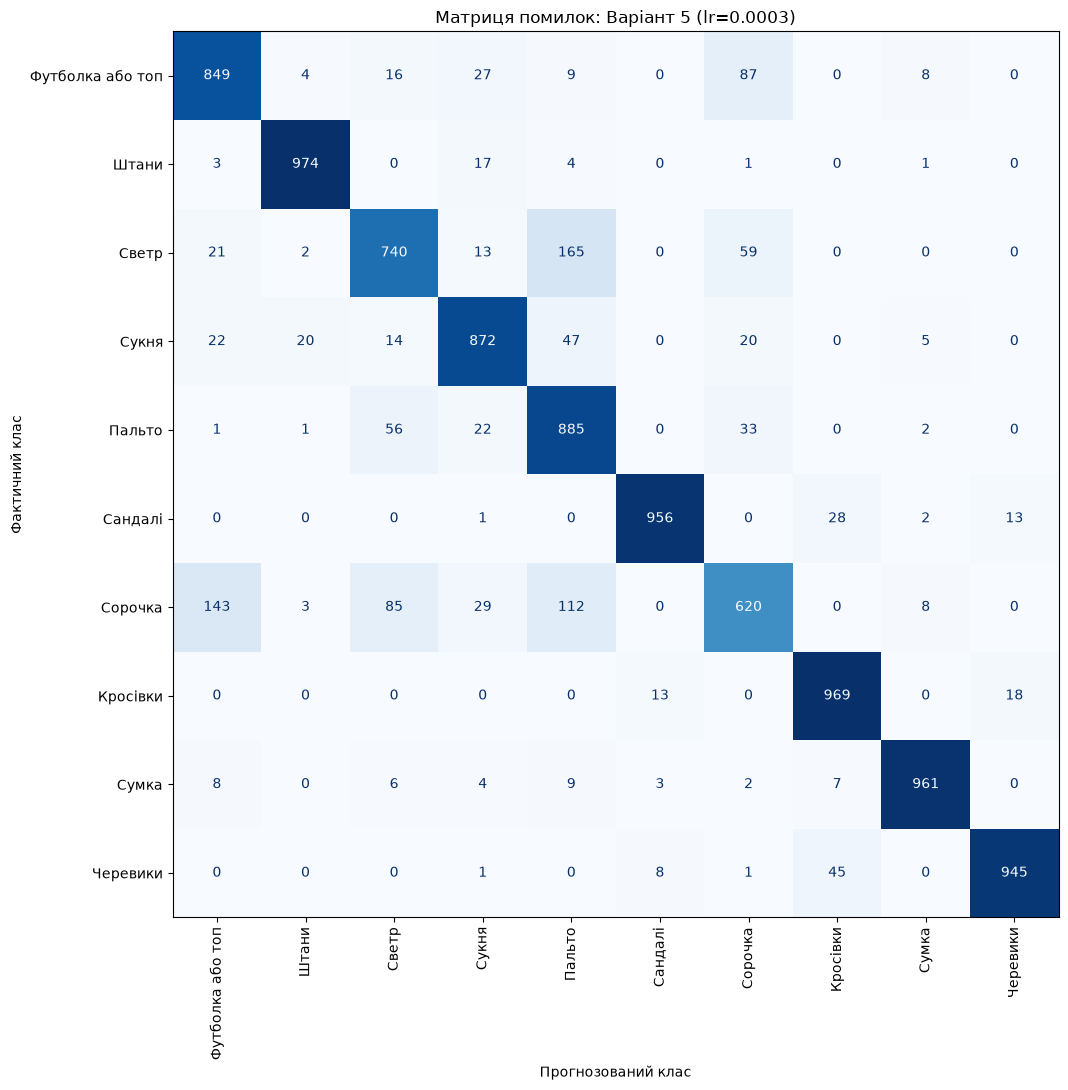

                  precision    recall  f1-score   support

Футболка або топ       0.81      0.85      0.83      1000
           Штани       0.97      0.97      0.97      1000
           Светр       0.81      0.74      0.77      1000
           Сукня       0.88      0.87      0.88      1000
          Пальто       0.72      0.89      0.79      1000
         Сандалі       0.98      0.96      0.97      1000
         Сорочка       0.75      0.62      0.68      1000
        Кросівки       0.92      0.97      0.95      1000
           Сумка       0.97      0.96      0.97      1000
        Черевики       0.97      0.94      0.96      1000

        accuracy                           0.88     10000
       macro avg       0.88      0.88      0.88     10000
    weighted avg       0.88      0.88      0.88     10000

Найчастіша плутанина: Светр → Пальто (165 випадків)

Футболка або топ: precision=0.811, recall=0.849, F1=0.830

Сорочка: precision=0.753, recall=0.620, F1=0.680


In [14]:
pred = probabilities.argmax(axis=1)

cm = confusion_matrix(
    y_test,
    pred,
    labels=np.arange(10),
)

fig, ax = plt.subplots(figsize=(13, 11))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
)

ax.set_title(f"Матриця помилок: {selected_model_name}")
ax.set_xlabel("Прогнозований клас")
ax.set_ylabel("Фактичний клас")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(
    y_test,
    pred,
    labels=np.arange(10),
    target_names=class_names,
    zero_division=0,
))

report = classification_report(
    y_test,
    pred,
    labels=np.arange(10),
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)

pd.DataFrame(report).T.to_csv("classification_report.csv")

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)

if off_diagonal.max() > 0:
    actual_id, predicted_id = np.unravel_index(
        off_diagonal.argmax(),
        off_diagonal.shape,
    )

    print(
        "Найчастіша плутанина:",
        f"{class_names[actual_id]} → {class_names[predicted_id]}",
        f"({off_diagonal[actual_id, predicted_id]} випадків)",
    )
else:
    print("Помилок класифікації немає.")

for class_id in [0, 6]:
    name = class_names[class_id]
    scores = report[name]

    print(
        f"\n{name}: "
        f"precision={scores['precision']:.3f}, "
        f"recall={scores['recall']:.3f}, "
        f"F1={scores['f1-score']:.3f}"
    )

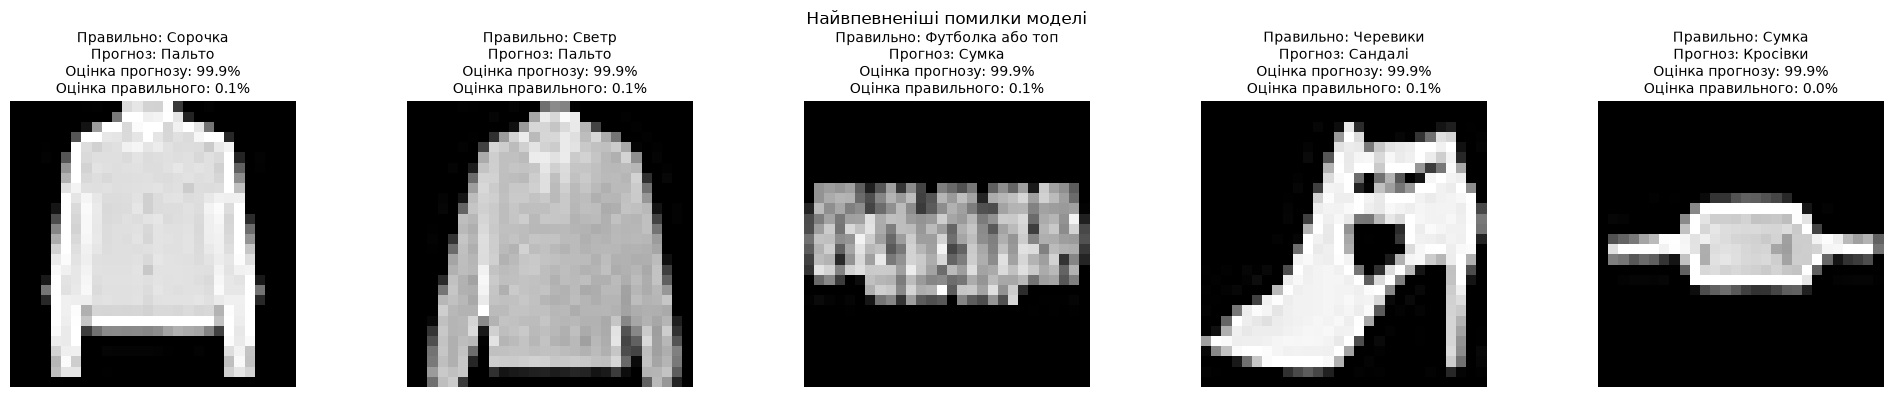

,test_index,actual_class,predicted_class,predicted_score,true_class_score
0,7258,Сорочка,Пальто,0.999162,0.000516
1,1743,Светр,Пальто,0.999064,0.000630
2,2599,Футболка або топ,Сумка,0.998914,0.000682
3,5946,Черевики,Сандалі,0.998910,0.001090
4,6565,Сумка,Кросівки,0.998860,0.000461


In [15]:
confidence = probabilities.max(axis=1)

wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]

if len(show_ids) > 0:
    fig, axes = plt.subplots(
        1, len(show_ids),
        figsize=(4 * len(show_ids), 4),
        squeeze=False,
    )

    error_rows = []

    for ax, image_id in zip(axes.flat, show_ids):
        actual_id = int(y_test[image_id])
        predicted_id = int(pred[image_id])
        true_class_score = float(
            probabilities[image_id, actual_id]
        )

        ax.imshow(
            x_test[image_id],
            cmap="gray",
            vmin=0,
            vmax=255,
        )
        ax.set_title(
            f"Правильно: {class_names[actual_id]}\n"
            f"Прогноз: {class_names[predicted_id]}\n"
            f"Оцінка прогнозу: {confidence[image_id]:.1%}\n"
            f"Оцінка правильного: {true_class_score:.1%}",
            fontsize=10,
        )
        ax.axis("off")

        error_rows.append({
            "test_index": int(image_id),
            "actual_class": class_names[actual_id],
            "predicted_class": class_names[predicted_id],
            "predicted_score": float(confidence[image_id]),
            "true_class_score": true_class_score,
        })

    fig.suptitle("Найвпевненіші помилки моделі")
    plt.tight_layout()
    plt.savefig(
        "confident_errors.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    confident_errors = pd.DataFrame(error_rows)
    confident_errors.to_csv("confident_errors.csv", index=False)
    display(confident_errors)
else:
    print("Помилок класифікації немає.")

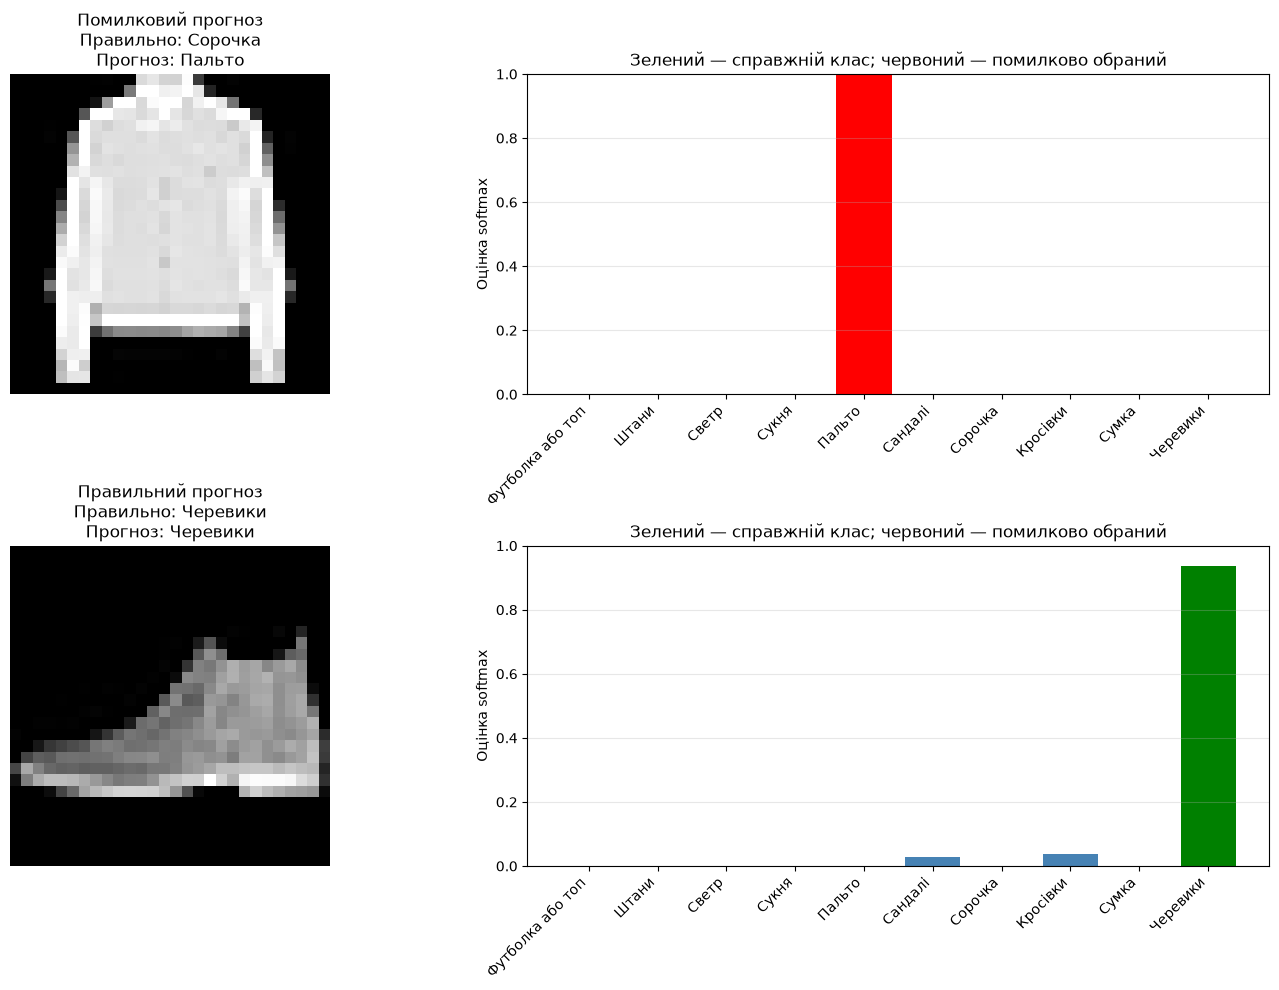

In [16]:
correct = np.flatnonzero(pred == y_test)

examples = []

if len(wrong) > 0:
    examples.append(("Помилковий прогноз", int(order[0])))

if len(correct) > 0:
    examples.append(("Правильний прогноз", int(correct[0])))

if examples:
    fig, axes = plt.subplots(
        len(examples), 2,
        figsize=(15, 5 * len(examples)),
        squeeze=False,
    )

    for row, (title, image_id) in enumerate(examples):
        actual_id = int(y_test[image_id])
        predicted_id = int(pred[image_id])

        axes[row, 0].imshow(
            x_test[image_id], cmap="gray", vmin=0, vmax=255
        )
        axes[row, 0].set_title(
            f"{title}\n"
            f"Правильно: {class_names[actual_id]}\n"
            f"Прогноз: {class_names[predicted_id]}"
        )
        axes[row, 0].axis("off")

        colors = ["steelblue"] * 10
        colors[actual_id] = "green"

        if predicted_id != actual_id:
            colors[predicted_id] = "red"

        axes[row, 1].bar(
            np.arange(10),
            probabilities[image_id],
            color=colors,
        )
        axes[row, 1].set_xticks(np.arange(10))
        axes[row, 1].set_xticklabels(
            class_names, rotation=45, ha="right"
        )
        axes[row, 1].set_ylim(0, 1)
        axes[row, 1].set_ylabel("Оцінка softmax")
        axes[row, 1].set_title(
            "Зелений — справжній клас; червоний — помилково обраний"
        )
        axes[row, 1].grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        "class_scores.png", dpi=150, bbox_inches="tight"
    )
    plt.show()
else:
    print("Немає прикладів для відображення.")

In [17]:
import json

model_path = artifacts_dir / "lab7_model.keras"
metadata_path = artifacts_dir / "metadata.json"
probe_path = artifacts_dir / "reload_probe.npz"

selected_model.save(model_path)

metadata = {
    "dataset": "Fashion-MNIST",
    "source": "https://github.com/zalandoresearch/fashion-mnist",
    "license": "MIT",
    "class_names": class_names,
    "input_shape": [28, 28],
    "input_dtype": "float32",
    "input_range": [0, 255],
    "preprocessing": "Rescaling(1/255) всередині моделі",
    "seed": SEED,
    "variant": 5,
    "variant_change": {
        "parameter": "learning_rate",
        "base": 0.001,
        "variant": 0.0003,
    },
    "selection_criterion": (
        "Мінімальна validation cross-entropy; "
        "за рівності обирається базова модель"
    ),
    "selected_model": selected_model_name,
    "train_indices": train_indices.tolist(),
    "validation_indices": val_indices.tolist(),
    "test_split": "Офіційний test без змін",
    "versions": {
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
    },
}

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

probe = x_val[:3]
before = selected_model(probe, training=False).numpy()

np.savez_compressed(
    probe_path,
    images=probe,
    labels=y_val[:3],
    probabilities=before,
)

restored_model = keras.models.load_model(model_path)
after = restored_model(probe, training=False).numpy()

np.testing.assert_allclose(
    before,
    after,
    rtol=1e-5,
    atol=1e-6,
)

print("Модель збережено:", model_path)
print("Метадані збережено:", metadata_path)
print("Приклади для перевірки:", probe_path)
print("Прогнози до та після завантаження збігаються.")

Модель збережено: artifacts\lab7_model.keras
Метадані збережено: artifacts\metadata.json
Приклади для перевірки: artifacts\reload_probe.npz
Прогнози до та після завантаження збігаються.


In [18]:
import json
from pathlib import Path

import numpy as np
from tensorflow import keras

artifacts_dir = Path("artifacts")

with (artifacts_dir / "metadata.json").open(
    encoding="utf-8"
) as file:
    loaded_metadata = json.load(file)

loaded_model = keras.models.load_model(
    artifacts_dir / "lab7_model.keras"
)

with np.load(artifacts_dir / "reload_probe.npz") as data:
    images = data["images"]
    labels = data["labels"]
    expected_probabilities = data["probabilities"]

loaded_probabilities = loaded_model(
    images, training=False
).numpy()

np.testing.assert_allclose(
    expected_probabilities,
    loaded_probabilities,
    rtol=1e-5,
    atol=1e-6,
)

# Прогноз для одного зображення: додаємо batch-вимір.
image = images[0]
single_probabilities = loaded_model(
    image[None, ...], training=False
).numpy()[0]

class_id = int(single_probabilities.argmax())
class_names = loaded_metadata["class_names"]

print("Перевірку після перезапуску пройдено.")
print("Фактичний клас:", class_names[int(labels[0])])
print("Прогноз:", class_names[class_id])
print(f"Оцінка прогнозу: {single_probabilities[class_id]:.2%}")

Перевірку після перезапуску пройдено.
Фактичний клас: Сандалі
Прогноз: Сандалі
Оцінка прогнозу: 96.36%


In [19]:
from pathlib import Path

versions = loaded_metadata["versions"]

requirements = "\n".join([
    f"tensorflow=={versions['tensorflow']}",
    f"numpy=={versions['numpy']}",
    f"pandas=={versions['pandas']}",
    f"scikit-learn=={versions['scikit-learn']}",
])

import matplotlib

requirements += f"\nmatplotlib=={matplotlib.__version__}\n"

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8",
)

print(requirements)
print("requirements.txt збережено.")

tensorflow==2.21.0
numpy==2.5.3
pandas==3.0.6
scikit-learn==1.9.1
matplotlib==3.11.2

requirements.txt збережено.


In [20]:
import pandas as pd
from IPython.display import Markdown, display

comparison = pd.read_csv("model_comparison.csv")
selected_name = loaded_metadata["selected_model"]

base_row = comparison.loc[
    comparison["Модель"] == "Базова (lr=0.001)"
].iloc[0]

variant_row = comparison.loc[
    comparison["Модель"] == "Варіант 5 (lr=0.0003)"
].iloc[0]

selected_row = comparison.loc[
    comparison["Модель"] == selected_name
].iloc[0]

variant_effect = (
    "Зменшення learning rate з 0.001 до 0.0003 покращило "
    "validation cross-entropy."
    if variant_row["Validation cross-entropy"]
    < base_row["Validation cross-entropy"]
    else
    "Зменшення learning rate з 0.001 до 0.0003 не покращило "
    "validation cross-entropy."
)

conclusion = f"""
## Висновок

У роботі побудовано дві Dense-нейромережі для класифікації
зображень Fashion-MNIST на 10 класів і порівняно їх із
DummyClassifier.

За validation cross-entropy обрано модель **{selected_name}**:
її значення становить
**{selected_row["Validation cross-entropy"]:.4f}**,
а на незалежній test-вибірці отримано accuracy
**{selected_row["Test accuracy"]:.2%}** і macro-F1
**{selected_row["Test macro-F1"]:.4f}**.

{variant_effect}

Графіки показали, що базова мережа досягла найкращого
validation loss на 12-й епосі, тоді як варіантна — на 30-й,
тому менша швидкість навчання потребувала більше епох.

Матриця помилок та приклади впевнених помилок показали,
що висока оцінка softmax не гарантує правильного класу,
а збереження моделі перевірено через збіг прогнозів
після завантаження.

Модель перевірена на зображеннях одягу розміром 28×28
у відтінках сірого; застосування до звичайних кольорових
фотографій потребує окремої підготовки та перевірки.
"""

display(Markdown(conclusion))


## Висновок

У роботі побудовано дві Dense-нейромережі для класифікації
зображень Fashion-MNIST на 10 класів і порівняно їх із
DummyClassifier.

За validation cross-entropy обрано модель **Варіант 5 (lr=0.0003)**:
її значення становить
**0.3157**,
а на незалежній test-вибірці отримано accuracy
**87.71%** і macro-F1
**0.8761**.

Зменшення learning rate з 0.001 до 0.0003 покращило validation cross-entropy.

Графіки показали, що базова мережа досягла найкращого
validation loss на 12-й епосі, тоді як варіантна — на 30-й,
тому менша швидкість навчання потребувала більше епох.

Матриця помилок та приклади впевнених помилок показали,
що висока оцінка softmax не гарантує правильного класу,
а збереження моделі перевірено через збіг прогнозів
після завантаження.

Модель перевірена на зображеннях одягу розміром 28×28
у відтінках сірого; застосування до звичайних кольорових
фотографій потребує окремої підготовки та перевірки.


In [21]:
readme = f"""# Лабораторна робота №7

Нейронна класифікація зображень у TensorFlow.

Студент: Михайло Вахнюк.
Варіант: 5.

## Дані

Fashion-MNIST: зображення одягу 28×28 пікселів у відтінках сірого,
10 класів.

Джерело: https://github.com/zalandoresearch/fashion-mnist
Ліцензія: MIT.

Дані отримуються автоматично через:
keras.datasets.fashion_mnist.load_data()

Повна копія датасету до репозиторію не додається.

Поділ: 48 000 train, 12 000 validation, 10 000 test.
SEED = 42. Для train/validation використано стратифікацію.

## Моделі

- DummyClassifier(strategy="most_frequent").
- Базова Dense-мережа: Adam, learning_rate=0.001.
- Варіант 5: та сама мережа, learning_rate=0.0003.

Архітектура: Rescaling → Flatten → Dense(128, ReLU)
→ Dense(10, softmax).

Масштабування пікселів із 0–255 до 0–1 включене в модель.
Мітки — цілі індекси 0–9, функція втрат —
SparseCategoricalCrossentropy(from_logits=False).

Спільні налаштування: batch_size=128, максимум 30 епох,
EarlyStopping(patience=4), checkpoint за val_loss.

## Вибір моделі

Критерій: найменша validation cross-entropy.
За рівності обирається базова мережа.
Обрана модель: {selected_name}.

Test використано для фінального оцінювання після вибору моделі.

## Файли

- Lab7_Vakhniuk.ipynb — виконаний ноутбук.
- requirements.txt — версії бібліотек.
- model_comparison.csv — порівняння моделей.
- classification_report.csv — метрики за класами.
- confident_errors.csv — найвпевненіші помилки, якщо вони є.
- class_examples.png — приклади класів.
- training_curves.png — графіки навчання.
- confusion_matrix.png — матриця помилок.
- confident_errors.png — приклади помилок, якщо вони є.
- class_scores.png — оцінки класів для окремих прикладів.
- artifacts/base_best.keras — найкраща базова мережа.
- artifacts/variant5_best.keras — найкраща варіантна мережа.
- artifacts/lab7_model.keras — обрана нейромережа.
- artifacts/metadata.json — порядок класів і параметри експерименту.
- artifacts/reload_probe.npz — три validation-приклади
  та прогнози для перевірки відновлення.

## Запуск

Встановити залежності:
python -m pip install -r requirements.txt

Відкрити ноутбук, вибрати відповідне Python-середовище
та виконувати комірки послідовно.
Робоча папка ядра має бути Lab7.

Для першого завантаження Fashion-MNIST потрібен інтернет.
Комірка перевірки відновлення може виконуватися окремо
після перезапуску ядра за наявності збережених артефактів.
"""

Path("README.md").write_text(readme, encoding="utf-8")
print("README.md збережено.")

README.md збережено.
